# Module 05: Orthogonality and Least Squares

Real data never fits a model exactly: with 1000 data points and 3 parameters, $X\mathbf{w} = \mathbf{y}$ has **no
solution**. Least squares finds the best compromise, and its answer is pure geometry: **project y onto the space
of things the model can produce.** That idea, "the error is orthogonal to what you can explain", is behind linear
regression, PCA, and much of signal processing.

**Learning goals**
- Projection onto a line and onto a subspace, as matrices
- Orthonormal bases and orthogonal matrices
- Gram–Schmidt and the QR decomposition
- Derive the normal equations $X^\top X\mathbf{w} = X^\top\mathbf{y}$ from geometry
- Fit lines and polynomials; why QR/`lstsq` beats the normal equations numerically

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. Projection onto a line, as a matrix
From module 02: $\text{proj}_{\mathbf{a}}\mathbf{b} = \frac{\mathbf{a}^\top\mathbf{b}}{\mathbf{a}^\top\mathbf{a}}\mathbf{a}$.
Regrouping gives a **projection matrix** $P = \frac{\mathbf{a}\mathbf{a}^\top}{\mathbf{a}^\top\mathbf{a}}$, so that
$\text{proj}_{\mathbf{a}}\mathbf{b} = P\mathbf{b}$.

Every projection matrix has two signature properties:
- $P^2 = P$: projecting twice changes nothing (you're already on the line).
- $P^\top = P$: it is symmetric (for orthogonal projections).

[[0.8 0.4]
 [0.4 0.2]]
P² = P: True   Pᵀ = P: True   rank: 1


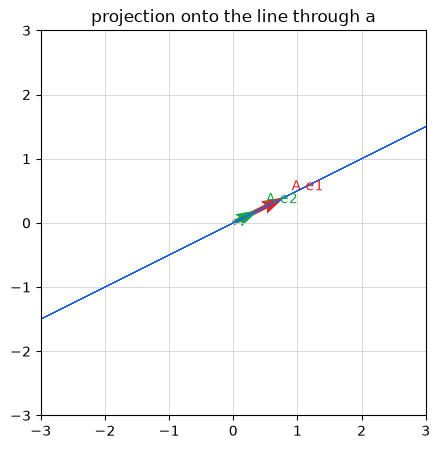

In [2]:
a = np.array([2.0, 1.0])
P = np.outer(a, a) / (a @ a)
print(P)
print("P² = P:", np.allclose(P @ P, P), "  Pᵀ = P:", np.allclose(P, P.T), "  rank:", np.linalg.matrix_rank(P))
mplt.plot_linear_transform(P, lim=3, title="projection onto the line through a")
plt.show()

## 2. Projection onto a subspace
Now project $\mathbf{b} \in \mathbb{R}^m$ onto the column space of a tall matrix $A$ (m×n, with m > n). We want the
point $A\hat{\mathbf{x}}$ in C(A) that is closest to b.

**The key insight:** at the closest point, the error $\mathbf{e} = \mathbf{b} - A\hat{\mathbf{x}}$ is
**perpendicular to every column of A**:
$$A^\top(\mathbf{b} - A\hat{\mathbf{x}}) = \mathbf{0} \quad\Longrightarrow\quad \boxed{A^\top A\,\hat{\mathbf{x}} = A^\top\mathbf{b}}$$
These are the **normal equations** ("normal" = perpendicular). If the columns of A are independent, $A^\top A$ is
invertible and
$$\hat{\mathbf{x}} = (A^\top A)^{-1}A^\top\mathbf{b}, \qquad P = A(A^\top A)^{-1}A^\top.$$

In [3]:
A = np.array([[1.0, 0.0], [1.0, 1.0], [1.0, 2.0]])     # a plane in R³
b = np.array([6.0, 0.0, 0.0])
x_hat = np.linalg.solve(A.T @ A, A.T @ b)
p = A @ x_hat
e = b - p
print("x̂ =", x_hat, " projection p =", p, " error e =", e)
print("error ⟂ columns:", (A.T @ e).round(12))

x̂ = [ 5. -3.]  projection p = [ 5.  2. -1.]  error e = [ 1. -2.  1.]
error ⟂ columns: [0. 0.]


/Users/surajsah/Documents/AI/ai-ml-math-foundation-zero-to-hero/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10178 (\N{PERPENDICULAR}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


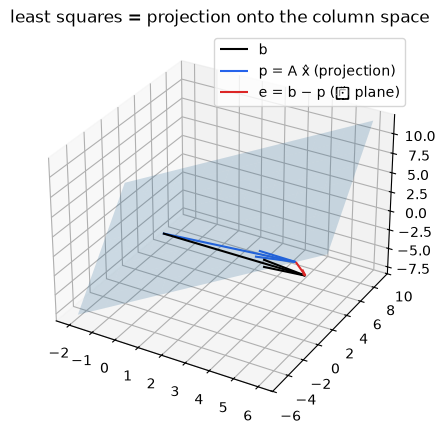

In [4]:
fig = plt.figure(figsize=(6, 5))
ax3 = fig.add_subplot(projection="3d")
s, t = np.meshgrid(np.linspace(-2, 6, 10), np.linspace(-3, 3, 10))
plane = s[..., None] * A[:, 0] + t[..., None] * A[:, 1]        # points in C(A)
ax3.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.2)
ax3.quiver(0, 0, 0, *b, color="k", label="b")
ax3.quiver(0, 0, 0, *p, color=mplt.COLORS[0], label="p = A x̂ (projection)")
ax3.quiver(*p, *e, color=mplt.COLORS[1], label="e = b − p (⟂ plane)")
ax3.legend(); ax3.set_title("least squares = projection onto the column space")
plt.show()

## 3. Orthonormal bases make everything easy
Vectors $\mathbf{q}_1, \dots, \mathbf{q}_n$ are **orthonormal** if they are mutually orthogonal and each has length 1:
$\mathbf{q}_i^\top\mathbf{q}_j = 0$ for i ≠ j and 1 for i = j. Stacked as the columns of Q, that's simply
$$Q^\top Q = I.$$
Then projection needs no inverse: $\hat{\mathbf{x}} = Q^\top\mathbf{b}$ and $P = QQ^\top$. Each coordinate is just a dot
product.

A **square** Q with orthonormal columns is an **orthogonal matrix**: $Q^{-1} = Q^\top$. It is a rotation (or
reflection), so it **preserves lengths and angles**: $\lVert Q\mathbf{x}\rVert = \lVert\mathbf{x}\rVert$. That's why
orthogonal weight initialization helps deep networks keep signals from exploding or vanishing.

In [5]:
Q, _ = np.linalg.qr(rng.normal(size=(5, 5)))       # a random orthogonal matrix
xv = rng.normal(size=5)
print("QᵀQ = I:", np.allclose(Q.T @ Q, np.eye(5)))
print("length kept:", np.linalg.norm(xv), np.linalg.norm(Q @ xv))
print("after 50 applications:", np.linalg.norm(np.linalg.matrix_power(Q, 50) @ xv))

QᵀQ = I: True
length kept: 0.947024506488832 0.9470245064888319
after 50 applications: 0.947024506488833


## 4. Gram–Schmidt: making a basis orthonormal
Start from independent vectors $\mathbf{a}_1, \mathbf{a}_2, \dots$ and straighten them one at a time:
1. $\mathbf{q}_1 = \mathbf{a}_1 / \lVert\mathbf{a}_1\rVert$
2. Take $\mathbf{a}_2$, **subtract its projections** onto all the q's found so far, then normalize.
3. Repeat.

What's left after subtracting is orthogonal to everything before it.

In [6]:
def gram_schmidt(A):
    Q = np.zeros_like(A, dtype=float)
    for j in range(A.shape[1]):
        v = A[:, j].astype(float)
        for i in range(j):
            v = v - (Q[:, i] @ A[:, j]) * Q[:, i]     # remove the component along q_i
        Q[:, j] = v / np.linalg.norm(v)
    return Q

A4 = rng.normal(size=(6, 3))
Q4 = gram_schmidt(A4)
print(np.round(Q4.T @ Q4, 10))

[[ 1. -0. -0.]
 [-0.  1. -0.]
 [-0. -0.  1.]]


### QR decomposition
Gram–Schmidt secretly factors $A = QR$. Q has orthonormal columns, and R is **upper-triangular** (it records the
projection coefficients). Libraries compute QR with a more stable algorithm (Householder reflections), but the idea is
the same.

With QR, least squares becomes $A^\top A\hat{\mathbf{x}} = A^\top\mathbf{b} \Rightarrow R^\top Q^\top Q R\hat{\mathbf{x}}
= R^\top Q^\top\mathbf{b} \Rightarrow \boxed{R\hat{\mathbf{x}} = Q^\top\mathbf{b}}$, which is solved by back-substitution
(module 04), with **no $A^\top A$ ever formed**.

In [7]:
Qr, R = np.linalg.qr(A4)          # "reduced" QR: Q is 6×3, R is 3×3
print("R upper-triangular:\n", R.round(3))
print("A = QR:", np.allclose(Qr @ R, A4))

R upper-triangular:
 [[-2.485  0.304  0.643]
 [ 0.    -1.589 -1.276]
 [ 0.     0.    -0.732]]
A = QR: True


## 5. Least squares in action: fitting a line
Model: $y \approx w_0 + w_1 x$. Stack one row per data point into a **design matrix** with a column of ones for
the intercept:
$$X = \begin{pmatrix} 1 & x_1 \\ 1 & x_2 \\ \vdots & \vdots \\ 1 & x_n \end{pmatrix}, \qquad
\hat{\mathbf{w}} = \arg\min_{\mathbf{w}} \lVert X\mathbf{w} - \mathbf{y}\rVert^2.$$
The minimizer of the squared error is exactly the projection from section 2. (Module 12 gets the same answer by
setting a gradient to zero.)

[1.2409 0.8246] [1.2409 0.8246] [1.2409 0.8246]


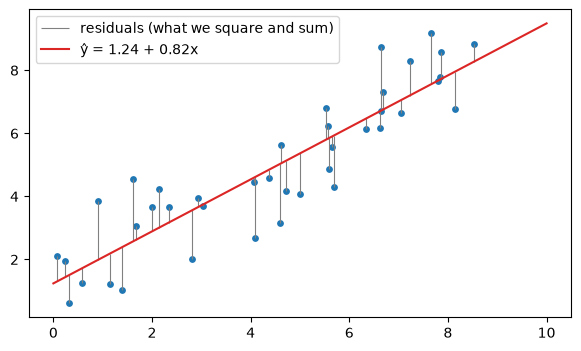

residuals ⟂ columns of X: [0. 0.]


In [8]:
n = 40
x_data = rng.uniform(0, 10, n)
y_data = 1.5 + 0.8 * x_data + rng.normal(0, 1.2, n)
X = np.column_stack([np.ones(n), x_data])

w_normal = np.linalg.solve(X.T @ X, X.T @ y_data)
Qx, Rx = np.linalg.qr(X)
w_qr = np.linalg.solve(Rx, Qx.T @ y_data)
w_lstsq, *_ = np.linalg.lstsq(X, y_data, rcond=None)
print(w_normal, w_qr, w_lstsq)

y_fit = X @ w_lstsq
plt.figure(figsize=(7, 4))
plt.vlines(x_data, y_fit, y_data, color="gray", lw=0.8, label="residuals (what we square and sum)")
plt.scatter(x_data, y_data, s=15)
xx = np.linspace(0, 10, 2)
plt.plot(xx, w_lstsq[0] + w_lstsq[1] * xx, color=mplt.COLORS[1], label=f"ŷ = {w_lstsq[0]:.2f} + {w_lstsq[1]:.2f}x")
plt.legend(); plt.show()
print("residuals ⟂ columns of X:", (X.T @ (y_data - y_fit)).round(10))

The residuals being orthogonal to the column of ones means **they sum to zero**. Every least-squares fit with an
intercept has residuals averaging exactly 0.

## 6. Polynomial fitting, and why you shouldn't form XᵀX
The model is still **linear in the weights** even if it's curved in x: just add columns $x^2, x^3, \dots$. That's
polynomial regression (ML course 09).

Numerically, though, $\kappa(X^\top X) = \kappa(X)^2$. **Forming XᵀX squares the condition number**, so you
lose twice as many digits. Watch the normal equations fall apart while `lstsq` (built on QR and SVD) holds up.

In [9]:
xp = np.linspace(0, 1, 50)
yp = np.sin(2 * np.pi * xp)
for deg in [3, 9, 15]:
    V = np.vander(xp, deg + 1, increasing=True)          # columns 1, x, x², ..., x^deg
    w_ne = np.linalg.solve(V.T @ V, V.T @ yp)
    w_ls, *_ = np.linalg.lstsq(V, yp, rcond=None)
    err_ne = np.linalg.norm(V @ w_ne - yp)
    err_ls = np.linalg.norm(V @ w_ls - yp)
    print(f"degree {deg:2d}: cond(X)={np.linalg.cond(V):.1e}  cond(XᵀX)={np.linalg.cond(V.T @ V):.1e}  "
          f"fit error normal-eq={err_ne:.1e}  lstsq={err_ls:.1e}")

degree  3: cond(X)=1.2e+02  cond(XᵀX)=1.4e+04  fit error normal-eq=5.1e-01  lstsq=5.1e-01
degree  9: cond(X)=3.6e+06  cond(XᵀX)=1.3e+13  fit error normal-eq=2.9e-05  lstsq=2.9e-05
degree 15: cond(X)=1.4e+11  cond(XᵀX)=1.1e+18  fit error normal-eq=5.6e-07  lstsq=4.5e-11


## Where you'll use this
- **ML course:** 07 linear regression (normal equation, `lstsq` inside scikit-learn's `LinearRegression`),
  09 polynomial features.
- **This course:** module 07 (SVD gives yet another least-squares solver), module 12 (the same result via gradients),
  module 23 capstone.
- **DL course:** 06 regularization (orthogonal init), 21 embeddings (projecting out directions).

## Summary
- A projection matrix satisfies P² = P = Pᵀ. Onto C(A): P = A(AᵀA)⁻¹Aᵀ.
- Least squares: the error is ⟂ to the columns, which gives AᵀA x̂ = Aᵀb.
- Orthonormal columns: QᵀQ = I, and projections become dot products. Orthogonal matrices preserve length.
- Gram–Schmidt produces A = QR, and least squares becomes R x̂ = Qᵀb.
- Prefer `lstsq`/QR over forming XᵀX, which squares the condition number.

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [Lecture 15: Projections onto Subspaces](https://www.youtube.com/watch?v=Y_Ac6KiQ1t0) (Gilbert Strang, MIT 18.06). Derives the normal equation by projection, exactly as the lesson does.
- [Lecture 17: Orthogonal Matrices and Gram-Schmidt](https://www.youtube.com/watch?v=0MtwqhIwdrI) (Gilbert Strang, MIT 18.06).

### 📘 Books and articles
- ⭐ [Introduction to Applied Linear Algebra (VMLS), ch. 12–13 (least squares, data fitting)](https://web.stanford.edu/~boyd/vmls/) (Boyd & Vandenberghe, 2018). Least squares as the workhorse of data fitting.
- [Mathematics for Machine Learning, ch. 3.8 (orthogonal projections)](https://mml-book.github.io/) (Deisenroth, Faisal & Ong, 2020).